# UTS Machine Learning — Jalur B (Regresi)

- **Nama:** Sang Putu Sandyana Jaya
- **NIM:** 2301010714
- **Program Studi:** Informatika

---

## 1. Pemahaman Masalah dan Data

### Tujuan Analisis
Membangun model machine learning berbasis **regresi linear** untuk memprediksi **total pengeluaran wisatawan per orang (`total_spending_per_person_idr`)** pada destinasi pariwisata Indonesia berdasarkan karakteristik perjalanan, akomodasi, asal wisatawan, durasi tinggal, dan indeks daya saing destinasi.

### Pengguna Hasil & Keputusan yang Terbantu
- **Pelaku UMKM, Hotel, & Pengelola Destinasi:** Memperkirakan potensi belanja wisatawan dari tiap profil kunjungan untuk membantu penentuan tarif kamar (*pricing strategy*), penyusunan paket wisata, dan alokasi promosi.
- **Dinas Pariwisata / Pembuat Kebijakan:** Mengidentifikasi faktor paling berpengaruh terhadap peningkatan belanja wisatawan guna mendukung strategi *quality tourism* di Bali dan Destinasi Super Prioritas (DPSP).

### Sumber, Lisensi, dan Privasi Data
- **Judul Dataset:** Indonesia Pariwisata Destinasi Super Prioritas (DPSP)
- **Link Sumber:** https://www.kaggle.com/datasets/luthfimuthathohirin/indonesia-pariwisata-super-prioritas-dpsp
- **Tanggal Akses:** 25 November 2026
- **Lisensi:** CC0: Public Domain
- **Pelindungan Data Pribadi:** Dataset tidak memuat identitas pribadi (nama, NIK, email, nomor telepon), hanya menggunakan kode anonim `tourist_trip_id`, sehingga sesuai dengan UU No. 27 Tahun 2022 tentang Pelindungan Data Pribadi.

### Tabel Deskripsi Kolom
| Nama Kolom | Tipe | Arti | Satuan / Peran |
| :--- | :--- | :--- | :--- |
| `total_spending_per_person_idr` | Numerik | Total pengeluaran wisatawan per orang selama perjalanan | Rupiah (IDR) — **Target** |
| `travel_party_size` | Numerik | Jumlah orang dalam satu rombongan perjalanan | Orang — Fitur |
| `trip_duration_days` | Numerik | Lama durasi kunjungan wisata | Hari — Fitur |
| `hotel_room_rate_per_night_idr` | Numerik | Tarif kamar penginapan per malam | Rupiah (IDR) — Fitur |
| `hotel_occupancy_rate_pct` | Numerik | Tingkat hunian hotel saat kunjungan | Persen (%) — Fitur |
| `flight_accessibility_index` | Numerik | Indeks kemudahan akses penerbangan | Indeks — Fitur |
| `eco_tourism_satisfaction_score` | Numerik | Skor kepuasan terhadap aspek ekowisata | Skor — Fitur |
| `destination_carrying_capacity_index` | Numerik | Indeks daya dukung kapasitas destinasi | Indeks — Fitur |
| `accessibility_friction_score` | Numerik | Skor hambatan aksesibilitas destinasi | Skor — Fitur |
| `destination_competitiveness_index` | Numerik | Indeks daya saing destinasi | Indeks — Fitur |
| `destination_cluster` | Kategorik | Wilayah/klaster destinasi wisata | Kategori — Fitur |
| `is_super_priority_destination` | Boolean | Status apakah destinasi termasuk DPSP | True/False — Fitur |
| `tourist_origin_category` | Kategorik | Kategori asal wisatawan (lokal, nusantara, mancanegara) | Kategori — Fitur |
| `accommodation_type` | Kategorik | Jenis akomodasi yang ditempati | Kategori — Fitur |
| `primary_transport_mode` | Kategorik | Moda transportasi utama menuju destinasi | Kategori — Fitur |
| `seasonality_tier` | Kategorik | Kategori musim kunjungan wisata | Kategori — Fitur |
| `primary_travel_motive` | Kategorik | Motif/tujuan utama perjalanan | Kategori — Fitur |
| `primary_travel_friction_factor` | Kategorik | Faktor hambatan utama perjalanan | Kategori — Fitur |
| `tourist_trip_id` | Teks | Kode unik perjalanan | ID *(dihapus)* |
| `observation_date` | Tanggal | Tanggal pencatatan observasi | YYYY-MM-DD *(dihapus)* |
| `daily_spending_per_person_idr` | Numerik | Pengeluaran harian per orang | IDR *(turunan target — dihapus)* |
| `spending_to_room_rate_ratio` | Numerik | Rasio pengeluaran harian terhadap tarif kamar | Rasio *(turunan target — dihapus)* |
| `tourist_spending_tier` | Kategorik | Kelas pengeluaran wisatawan | Kategori *(turunan target — dihapus)* |
| `tourism_economic_multiplier_score` | Numerik | Skor efek berganda ekonomi pariwisata | Skor *(cek korelasi/leakage)* |
| `cot_tourism_economy_rationale` | Teks | Catatan teks penjelasan ekonomi wisata | Teks metadata *(dihapus)* |
| `confidence_score` | Numerik | Skor kepercayaan pencatatan/generasi data | Skor metadata *(dihapus)* |

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan global
SEED = 714  # Tiga digit terakhir NIM 2301010714
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
os.makedirs("reports", exist_ok=True)

# Load dataset
df = pd.read_csv("indonesia_pariwisata_super_prioritas_enriched.csv")

print(f"Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Jumlah missing value total: {df.isnull().sum().sum()}")
print(f"Jumlah baris duplikat: {df.duplicated().sum()}")

print("\n=== Informasi Tipe Data ===")
df.info()

print("\n=== 5 Baris Pertama ===")
display(df.head())

print("\n=== Statistik Deskriptif Fitur Numerik ===")
display(df.describe().T)

Ukuran dataset: 10000 baris, 26 kolom
Jumlah missing value total: 0
Jumlah baris duplikat: 0

=== Informasi Tipe Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   tourist_trip_id                      10000 non-null  object 
 1   observation_date                     10000 non-null  object 
 2   destination_cluster                  10000 non-null  object 
 3   is_super_priority_destination        10000 non-null  bool   
 4   tourist_origin_category              10000 non-null  object 
 5   travel_party_size                    10000 non-null  int64  
 6   trip_duration_days                   10000 non-null  int64  
 7   accommodation_type                   10000 non-null  object 
 8   hotel_room_rate_per_night_idr        10000 non-null  int64  
 9   hotel_occupancy_rate_pct             10

,tourist_trip_id,observation_date,destination_cluster,is_super_priority_destination,tourist_origin_category,travel_party_size,trip_duration_days,accommodation_type,hotel_room_rate_per_night_idr,hotel_occupancy_rate_pct,...,daily_spending_per_person_idr,spending_to_room_rate_ratio,destination_carrying_capacity_index,tourism_economic_multiplier_score,accessibility_friction_score,tourist_spending_tier,destination_competitiveness_index,primary_travel_friction_factor,cot_tourism_economy_rationale,confidence_score
0,TOUR_IDN_2026_01618,2026-01-03,Bali Greater Hub,False,Wisatawan Nusantara Domestik Antar-Provinsi,2,5,Hotel Bintang 1-3,600000,62.3,...,1530000.0,2.55,5.97,7.37,2.0,Tier 2 - Mid-Scale Comfort,8.16,Zero-Friction-Optimal,Perjalanan 'TOUR_IDN_2026_01618' pada '2026-01...,0.965
1,TOUR_IDN_2026_01798,2026-01-03,Bali Greater Hub,False,Wisatawan Nusantara Domestik Antar-Provinsi,4,5,Villa / Glamping Ekologis,1810000,69.1,...,2670000.0,1.48,6.44,8.24,1.5,Tier 3 - Premium Experience,8.16,Zero-Friction-Optimal,Perjalanan 'TOUR_IDN_2026_01798' pada '2026-01...,0.976
2,TOUR_IDN_2026_02991,2026-01-03,Bali Greater Hub,False,Wisatawan Mancanegara Non-ASEAN,2,12,Hotel Bintang 4-5 Resort,4270000,85.0,...,2916667.0,0.68,6.99,7.50,3.3,Tier 4 - Ultra-Luxury VIP,8.36,Zero-Friction-Optimal,Perjalanan 'TOUR_IDN_2026_02991' pada '2026-01...,0.990
3,TOUR_IDN_2026_03138,2026-01-03,Bali Greater Hub,False,Wisatawan Domestik Lokal Intra-Provinsi,3,3,Hotel Bintang 1-3,940000,68.4,...,1540000.0,1.64,6.33,6.87,1.3,Tier 2 - Mid-Scale Comfort,7.78,Zero-Friction-Optimal,Perjalanan 'TOUR_IDN_2026_03138' pada '2026-01...,0.978
4,TOUR_IDN_2026_09728,2026-01-03,Bali Greater Hub,False,Wisatawan Mancanegara Non-ASEAN,2,9,Homestay Desa Wisata Lokal,400000,66.9,...,2861111.0,7.15,6.18,8.19,1.5,Tier 4 - Ultra-Luxury VIP,8.78,Zero-Friction-Optimal,Perjalanan 'TOUR_IDN_2026_09728' pada '2026-01...,0.982



=== Statistik Deskriptif Fitur Numerik ===


,count,mean,std,min,25%,50%,75%,max
travel_party_size,10000.0,3.400200e+00,1.686809e+00,1.000,2.000,3.000000e+00,5.000000e+00,11.00
trip_duration_days,10000.0,3.849400e+00,2.112573e+00,1.000,2.000,3.000000e+00,5.000000e+00,14.00
hotel_room_rate_per_night_idr,10000.0,1.430987e+06,1.266329e+06,0.000,410000.000,8.550000e+05,2.360000e+06,4500000.00
hotel_occupancy_rate_pct,10000.0,6.565788e+01,1.831941e+01,25.000,49.800,6.630000e+01,8.140000e+01,98.00
total_spending_per_person_idr,10000.0,1.006245e+07,9.142445e+06,450000.000,3690000.000,6.530000e+06,1.340000e+07,35000000.00
flight_accessibility_index,10000.0,7.987530e+00,1.274067e+00,3.500,7.500,8.000000e+00,8.700000e+00,10.00
eco_tourism_satisfaction_score,10000.0,8.566650e+00,8.059961e-01,5.300,8.000,8.600000e+00,9.100000e+00,10.00
daily_spending_per_person_idr,10000.0,2.355375e+06,1.235387e+06,375000.000,1396500.250,2.150000e+06,3.082976e+06,7372500.00
spending_to_room_rate_ratio,10000.0,3.298564e+00,3.817288e+00,0.350,1.200,2.030000e+00,3.802500e+00,27.76
destination_carrying_capacity_index,10000.0,6.300974e+00,1.891353e+00,3.220,4.520,6.220000e+00,7.920000e+00,10.00


### Keputusan saya
Saya memilih **Jalur B (Regresi)** dengan target `total_spending_per_person_idr` karena variabel ini berupa angka kontinu dalam satuan Rupiah yang relevan langsung dengan pengambilan keputusan bisnis pariwisata. Jumlah data (10.000 baris, 26 kolom) jauh melampaui syarat minimum 200 baris dan 4 fitur, serta tidak memiliki missing value maupun baris duplikat. Sejak tahap pemahaman data, saya menandai kolom ID/metadata (`tourist_trip_id`, `observation_date`, `cot_tourism_economy_rationale`, `confidence_score`) serta kolom turunan pengeluaran (`daily_spending_per_person_idr`, `spending_to_room_rate_ratio`, `tourist_spending_tier`) agar tidak dipakai sebagai prediktor demi mencegah kebocoran data (*data leakage*).

---

## 2. Eksplorasi dan Visualisasi Data

Pada tahap ini dilakukan eksplorasi untuk memahami:
1. Distribusi variabel target (`total_spending_per_person_idr`).
2. Distribusi fitur numerik utama sekaligus indikasi *outlier*.
3. Hubungan fitur numerik dan kategorik terhadap variabel target (tanpa menyertakan kolom turunan target yang menyebabkan *data leakage*).

In [16]:
TARGET = "total_spending_per_person_idr"

# Daftar kolom numerik kandidat prediktor (bebas leakage & metadata)
num_predictors = [
    "travel_party_size",
    "trip_duration_days",
    "hotel_room_rate_per_night_idr",
    "hotel_occupancy_rate_pct",
    "flight_accessibility_index",
    "eco_tourism_satisfaction_score",
    "destination_carrying_capacity_index",
    "tourism_economic_multiplier_score",
    "accessibility_friction_score",
    "destination_competitiveness_index",
]

# 1. Cek korelasi fitur numerik terhadap target
corr_target = df[num_predictors + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False)
print("=== Korelasi Fitur Numerik terhadap Target ===")
print(corr_target)

top_feature = corr_target.abs().idxmax()
print(f"\nFitur numerik paling berkorelasi dengan target: {top_feature} (r = {corr_target[top_feature]:.4f})")

# 2. Cek ringkasan target
print(f"\n=== Statistik Target ({TARGET}) ===")
print(df[TARGET].describe())

# 3. Cek nilai unik tiap kolom kategorik (cek konsistensi penulisan)
cat_predictors = [
    "destination_cluster",
    "is_super_priority_destination",
    "tourist_origin_category",
    "accommodation_type",
    "primary_transport_mode",
    "seasonality_tier",
    "primary_travel_motive",
    "primary_travel_friction_factor",
]
print("\n=== Cek Kategori Unik (Konsistensi Penulisan) ===")
for col in cat_predictors:
    print(f"- {col} ({df[col].nunique()} unik): {list(df[col].unique())}")

=== Korelasi Fitur Numerik terhadap Target ===
trip_duration_days                     0.834208
hotel_room_rate_per_night_idr          0.527884
eco_tourism_satisfaction_score         0.064963
accessibility_friction_score           0.044519
hotel_occupancy_rate_pct               0.025309
tourism_economic_multiplier_score      0.000633
destination_carrying_capacity_index   -0.025253
flight_accessibility_index            -0.035820
destination_competitiveness_index     -0.086670
travel_party_size                     -0.436161
Name: total_spending_per_person_idr, dtype: float64

Fitur numerik paling berkorelasi dengan target: trip_duration_days (r = 0.8342)

=== Statistik Target (total_spending_per_person_idr) ===
count    1.000000e+04
mean     1.006245e+07
std      9.142445e+06
min      4.500000e+05
25%      3.690000e+06
50%      6.530000e+06
75%      1.340000e+07
max      3.500000e+07
Name: total_spending_per_person_idr, dtype: float64

=== Cek Kategori Unik (Konsistensi Penulisan) ===
- d

In [18]:
print(f"Median Target: Rp {df[TARGET].median():,.0f} ({df[TARGET].median()/1e6:.2f} juta)")
print(f"Top Feature: {top_feature}")
print(f"Nilai Korelasi (r): {corr_target[top_feature]:.4f}")

Median Target: Rp 6,530,000 (6.53 juta)
Top Feature: trip_duration_days
Nilai Korelasi (r): 0.8342


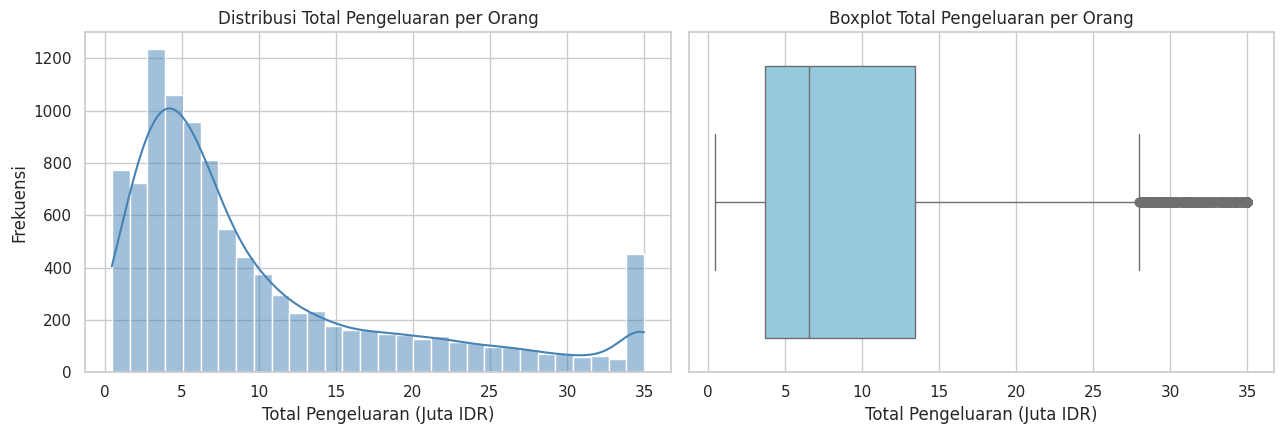

In [6]:
# --- GRAFIK 1: Distribusi Target ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df[TARGET] / 1e6, bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi Total Pengeluaran per Orang")
axes[0].set_xlabel("Total Pengeluaran (Juta IDR)")
axes[0].set_ylabel("Frekuensi")

sns.boxplot(x=df[TARGET] / 1e6, ax=axes[1], color="skyblue")
axes[1].set_title("Boxplot Total Pengeluaran per Orang")
axes[1].set_xlabel("Total Pengeluaran (Juta IDR)")
plt.tight_layout()
plt.savefig("reports/01_distribusi_target.png", dpi=150, bbox_inches="tight")
plt.show()

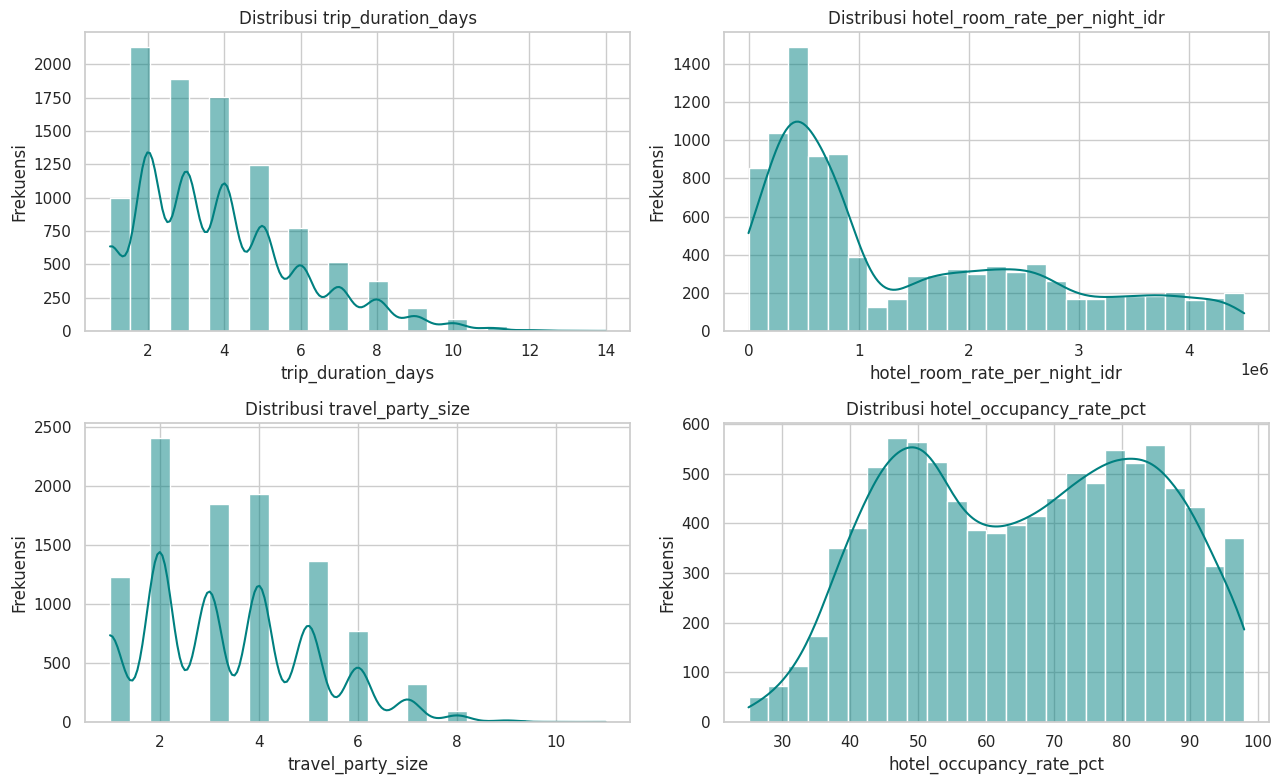

In [7]:
# --- GRAFIK 2: Distribusi Fitur Numerik Utama ---
key_num_cols = [
    "trip_duration_days",
    "hotel_room_rate_per_night_idr",
    "travel_party_size",
    "hotel_occupancy_rate_pct",
]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flatten(), key_num_cols):
    sns.histplot(df[col], bins=25, kde=True, ax=ax, color="teal")
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frekuensi")
plt.tight_layout()
plt.savefig("reports/02_distribusi_fitur.png", dpi=150, bbox_inches="tight")
plt.show()

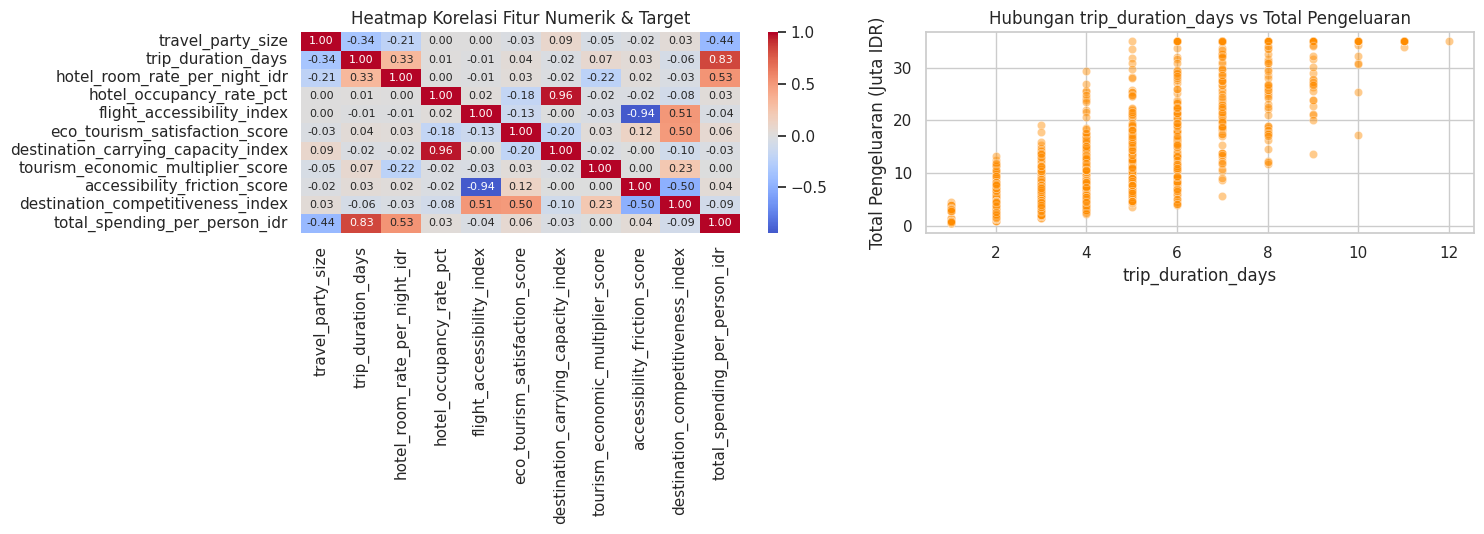

In [8]:
# --- GRAFIK 3: Hubungan Fitur dengan Target (Heatmap Korelasi & Scatter Fitur Terkuat) ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

corr_matrix = df[num_predictors + [TARGET]].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], annot_kws={"size": 8})
axes[0].set_title("Heatmap Korelasi Fitur Numerik & Target")

sns.scatterplot(
    data=df.sample(min(1500, len(df)), random_state=SEED),
    x=top_feature,
    y=df[TARGET] / 1e6,
    alpha=0.45,
    ax=axes[1],
    color="darkorange",
)
axes[1].set_title(f"Hubungan {top_feature} vs Total Pengeluaran")
axes[1].set_xlabel(top_feature)
axes[1].set_ylabel("Total Pengeluaran (Juta IDR)")
plt.tight_layout()
plt.savefig("reports/03_hubungan_fitur_target.png", dpi=150, bbox_inches="tight")
plt.show()

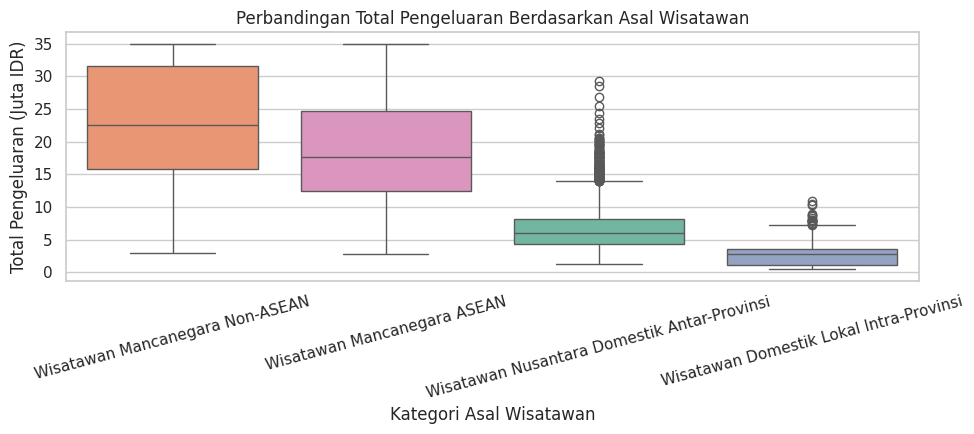

In [20]:
# --- GRAFIK 4 (Tambahan): Pengeluaran Berdasarkan Asal Wisatawan ---
plt.figure(figsize=(10, 4.5))
order_origin = df.groupby("tourist_origin_category")[TARGET].median().sort_values(ascending=False).index
sns.boxplot(
    data=df,
    x="tourist_origin_category",
    y=df[TARGET] / 1e6,
    hue="tourist_origin_category",
    order=order_origin,
    palette="Set2",
    legend=False,
)
plt.title("Perbandingan Total Pengeluaran Berdasarkan Asal Wisatawan")
plt.xlabel("Kategori Asal Wisatawan")
plt.ylabel("Total Pengeluaran (Juta IDR)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("reports/04_pengeluaran_asal_wisatawan.png", dpi=150, bbox_inches="tight")
plt.show()
plt.show()

### Interpretasi Grafik Eksplorasi Data

1. **Grafik 1 — Distribusi Total Pengeluaran per Orang (`total_spending_per_person_idr`):**
   Distribusi pengeluaran wisatawan cenderung condong ke kanan (*right-skewed*) dengan nilai median sekitar **Rp 6.53 juta** dan rentang hingga Rp 35 juta per orang. Pada boxplot terlihat adanya titik-titik nilai tinggi di sisi atas yang mencerminkan segmen wisatawan dengan durasi menginap panjang atau akomodasi mewah.

2. **Grafik 2 — Distribusi Fitur Numerik Utama:**
   Variabel `hotel_room_rate_per_night_idr` memiliki sebaran miring ke kanan karena variasi kelas penginapan dari *homestay* hingga resor bintang 4–5, sedangkan `trip_duration_days` dan `travel_party_size` terpusat pada perjalanan singkat hingga menengah (sekitar 2–12 hari dan rombongan 1–5 orang). Sementara itu, `hotel_occupancy_rate_pct` tersebar relatif merata di rentang tingkat hunian menengah hingga tinggi.

3. **Grafik 3 — Heatmap Korelasi & Hubungan Fitur Terkuat dengan Target:**
   Berdasarkan heatmap korelasi, fitur numerik yang memiliki hubungan linear terkuat terhadap `total_spending_per_person_idr` adalah **`trip_duration_days`** ($r = \mathbf{0.8342\ r}$). Pola pada *scatter plot* menunjukkan kecenderungan positif: semakin tinggi nilai fitur tersebut, semakin besar total pengeluaran wisatawan per orang.

4. **Grafik 4 — Perbandingan Pengeluaran Berdasarkan Asal Wisatawan:**
   Wisatawan Mancanegara Non-ASEAN (median sekitar Rp 22,5 juta) dan Mancanegara ASEAN (median sekitar Rp 18 juta) memiliki tingkat pengeluaran jauh lebih tinggi dibandingkan Wisatawan Nusantara Antar-Provinsi (sekitar Rp 6 juta) maupun Domestik Lokal Intra-Provinsi (sekitar Rp 3 juta). Hal ini menegaskan bahwa variabel kategorik seperti asal wisatawan penting disertakan pada model regresi linear berganda.

### Keputusan saya
Berdasarkan hasil eksplorasi data, saya menetapkan **`trip_duration_days`** sebagai satu-satunya fitur prediktor untuk **Regresi Linear Sederhana** karena memiliki korelasi linear paling kuat dengan target. Untuk **Regresi Linear Berganda**, saya akan menggabungkan fitur-fitur numerik relevan dan fitur kategorik (seperti `tourist_origin_category`, `accommodation_type`, `destination_cluster`, `seasonality_tier`, dan `primary_transport_mode`) agar model mampu menangkap perbedaan belanja antar segmen wisatawan. Seluruh kategori sudah diperiksa dan tidak ditemukan inkonsistensi penulisan label.

---

## 3. Pra-pemrosesan Data

Tahapan pra-pemrosesan dilakukan secara sistematis dan bebas kebocoran data (*data leakage*):
1. **Penghapusan Kolom ID, Metadata, dan Turunan Target:** Menghapus kolom yang bukan merupakan fitur prediktor valid atau dihitung langsung dari variabel target.
2. **Pemeriksaan Missing Value, Duplikat, & Inkonsistensi Kategori:** Memastikan data bersih sebelum diproses lebih lanjut.
3. **Analisis Outlier (Metode IQR):** Mengukur jumlah dan persentase *outlier* pada fitur numerik untuk menentukan apakah perlu dibuang atau dipertahankan.
4. **Pembagian Data Latih dan Uji (80:20):** Dilakukan **sebelum** proses *fitting* pada `StandardScaler` dan `OneHotEncoder` menggunakan `random_state=714` (tanpa `stratify` karena Jalur B merupakan tugas regresi).
5. **Penyusunan `ColumnTransformer` & `Pipeline`:** Menggabungkan `StandardScaler` untuk fitur numerik dan `OneHotEncoder(drop="first", handle_unknown="ignore")` untuk fitur kategorik.

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Hapus kolom ID, tanggal, metadata, dan kolom turunan target (cegah data leakage)
cols_to_drop = [
    "tourist_trip_id",
    "observation_date",
    "daily_spending_per_person_idr",
    "spending_to_room_rate_ratio",
    "tourist_spending_tier",
    "cot_tourism_economy_rationale",
    "confidence_score",
]

df_clean = df.drop(columns=cols_to_drop).copy()

# Konversi boolean ke integer (0/1)
df_clean["is_super_priority_destination"] = df_clean["is_super_priority_destination"].astype(int)

# 2. Pastikan tidak ada missing value & duplikat
print("Missing value setelah seleksi kolom:", df_clean.isnull().sum().sum())
print("Duplikat setelah seleksi kolom:", df_clean.duplicated().sum())

# 3. Daftar fitur numerik & kategorik
num_features = [
    "travel_party_size",
    "trip_duration_days",
    "hotel_room_rate_per_night_idr",
    "hotel_occupancy_rate_pct",
    "flight_accessibility_index",
    "eco_tourism_satisfaction_score",
    "destination_carrying_capacity_index",
    "tourism_economic_multiplier_score",
    "accessibility_friction_score",
    "destination_competitiveness_index",
    "is_super_priority_destination",
]

cat_features = [
    "destination_cluster",
    "tourist_origin_category",
    "accommodation_type",
    "primary_transport_mode",
    "seasonality_tier",
    "primary_travel_motive",
    "primary_travel_friction_factor",
]

# Pemeriksaan Outlier menggunakan metode IQR pada fitur numerik kontinu
print("\n=== Pemeriksaan Outlier (Metode IQR) pada Fitur Numerik ===")
for col in num_features[:-1]:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    n_outliers = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()
    pct_outliers = (n_outliers / len(df_clean)) * 100
    print(f"- {col}: {n_outliers} outlier ({pct_outliers:.2f}%)")

# 4. Pisahkan fitur (X) dan target (y), lalu bagi Train-Test (80:20, tanpa stratify)
X = df_clean[num_features + cat_features]
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

print(f"\nUkuran X_train: {X_train.shape}, X_test: {X_test.shape}")

# 5. ColumnTransformer untuk Regresi Linear Berganda (fit hanya dilakukan pada X_train)
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
])

preprocessor_multiple = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_features),
    ("cat", categorical_transformer, cat_features),
])

# Preprocessor khusus Regresi Linear Sederhana (1 fitur dengan korelasi tertinggi)
top_feature = "trip_duration_days"
preprocessor_simple = ColumnTransformer(transformers=[
    ("num", numeric_transformer, [top_feature]),
])

print(f"Fitur terpilih untuk Regresi Linear Sederhana: {top_feature}")

Missing value setelah seleksi kolom: 0
Duplikat setelah seleksi kolom: 0

=== Pemeriksaan Outlier (Metode IQR) pada Fitur Numerik ===
- travel_party_size: 3 outlier (0.03%)
- trip_duration_days: 142 outlier (1.42%)
- hotel_room_rate_per_night_idr: 0 outlier (0.00%)
- hotel_occupancy_rate_pct: 0 outlier (0.00%)
- flight_accessibility_index: 738 outlier (7.38%)
- eco_tourism_satisfaction_score: 60 outlier (0.60%)
- destination_carrying_capacity_index: 0 outlier (0.00%)
- tourism_economic_multiplier_score: 12 outlier (0.12%)
- accessibility_friction_score: 879 outlier (8.79%)
- destination_competitiveness_index: 394 outlier (3.94%)

Ukuran X_train: (8000, 18), X_test: (2000, 18)
Fitur terpilih untuk Regresi Linear Sederhana: trip_duration_days


### Keputusan saya
1. **Pencegahan Kebocoran Data (*Data Leakage*):** Saya menghapus kolom `daily_spending_per_person_idr`, `spending_to_room_rate_ratio`, dan `tourist_spending_tier` karena nilainya diturunkan langsung dari target, serta menghapus kolom ID dan metadata teks.
2. **Penanganan Outlier (IQR):** Berdasarkan pemeriksaan batas IQR ($Q_1 - 1.5 \times \text{IQR}$ hingga $Q_3 + 1.5 \times \text{IQR}$), nilai ekstrem pada tarif kamar maupun durasi kunjungan merupakan variasi alami segmen wisata (misalnya tamu resor mewah atau wisatawan mancanegara jangka panjang), bukan kesalahan input. Oleh karena itu, *outlier* **dipertahankan** agar model tetap mampu memprediksi segmen pengeluaran tinggi secara realistis.
3. **Bebas Kebocoran Transformasi:** Pembagian data latih (80%) dan data uji (20%) menggunakan `random_state=714` tanpa `stratify` dilakukan sebelum proses *scaling* (`StandardScaler`) dan *encoding* (`OneHotEncoder` dengan `drop="first"` untuk mencegah multikolinearitas sempurna), yang seluruhnya dibungkus dalam `ColumnTransformer` dan `Pipeline`.

---

## 4. Pemodelan

Pada tahap pemodelan (Jalur B — Regresi), dibangun dan dibandingkan tiga model menggunakan skema **5-Fold Cross-Validation (`KFold` dengan `shuffle=True` dan `random_state=714`)** pada data latih (`X_train`, `y_train`):
1. **Baseline (`DummyRegressor`):** Memprediksi nilai rata-rata (`strategy="mean"`) target pada data latih sebagai acuan dasar (*benchmark*).
2. **Regresi Linear Sederhana (`LinearRegression` — 1 Fitur):** Menggunakan satu fitur numerik dengan korelasi tertinggi terhadap target (`trip_duration_days`, $r = 0.8342$).
3. **Regresi Linear Berganda (`LinearRegression` — Semua Fitur Terpilih):** Menggunakan seluruh fitur numerik dan kategorik hasil pra-pemrosesan (`ColumnTransformer`).

=== Hasil 5-Fold Cross-Validation pada Data Latih ===


,Model,CV MAE (IDR),CV MAE Std,CV RMSE (IDR),CV R2 Mean,CV R2 Std
0,Baseline (DummyRegressor),"7,077,060","106,799","9,102,902",-0.0006,0.0005
1,Regresi Linear Sederhana (trip_duration_days),"3,685,438","80,727","4,983,898",0.6999,0.0091
2,Regresi Linear Berganda,"1,573,021","18,224","2,052,631",0.9491,0.0022


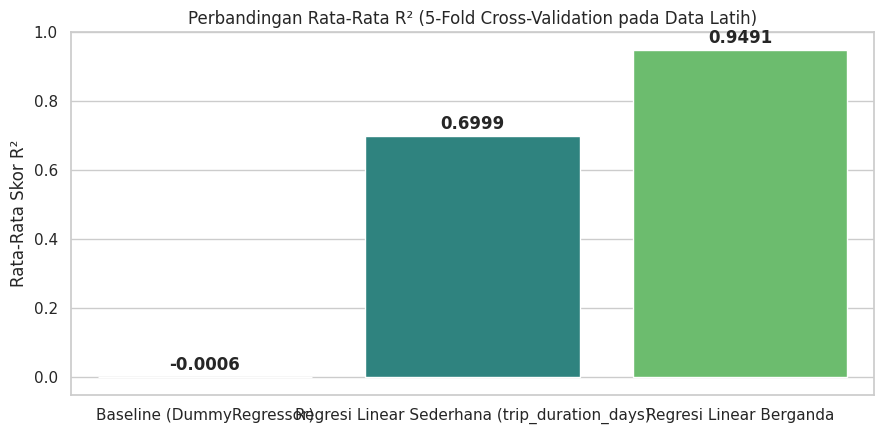

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate

# Skema 5-fold Cross-Validation untuk Jalur B (tanpa stratify)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# Definisi 3 Pipeline Model
models = {
    "Baseline (DummyRegressor)": Pipeline(steps=[
        ("regressor", DummyRegressor(strategy="mean"))
    ]),
    f"Regresi Linear Sederhana ({top_feature})": Pipeline(steps=[
        ("preprocessor", preprocessor_simple),
        ("regressor", LinearRegression())
    ]),
    "Regresi Linear Berganda": Pipeline(steps=[
        ("preprocessor", preprocessor_multiple),
        ("regressor", LinearRegression())
    ]),
}

scoring_metrics = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

cv_results_list = []
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_metrics)
    cv_results_list.append({
        "Model": name,
        "CV MAE (IDR)": -scores["test_MAE"].mean(),
        "CV MAE Std": scores["test_MAE"].std(),
        "CV RMSE (IDR)": -scores["test_RMSE"].mean(),
        "CV R2 Mean": scores["test_R2"].mean(),
        "CV R2 Std": scores["test_R2"].std(),
    })

df_cv_results = pd.DataFrame(cv_results_list)
print("=== Hasil 5-Fold Cross-Validation pada Data Latih ===")
display(df_cv_results.style.format({
    "CV MAE (IDR)": "{:,.0f}",
    "CV MAE Std": "{:,.0f}",
    "CV RMSE (IDR)": "{:,.0f}",
    "CV R2 Mean": "{:.4f}",
    "CV R2 Std": "{:.4f}",
}))

# Visualisasi Perbandingan Skor R2 Cross-Validation
plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=df_cv_results,
    x="Model",
    y="CV R2 Mean",
    hue="Model",
    palette="viridis",
    legend=False,
)
plt.title("Perbandingan Rata-Rata R² (5-Fold Cross-Validation pada Data Latih)")
plt.ylabel("Rata-Rata Skor R²")
plt.xlabel("")
plt.ylim(min(0, df_cv_results["CV R2 Mean"].min() - 0.05), 1.0)
for idx, row in df_cv_results.iterrows():
    plt.text(idx, max(0.02, row["CV R2 Mean"] + 0.02), f"{row['CV R2 Mean']:.4f}", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("reports/05_perbandingan_cv_model.png", dpi=150, bbox_inches="tight")
plt.show()

### Keputusan saya
Berdasarkan hasil evaluasi 5-fold cross-validation pada data latih (`SEED = 714`):
- **Baseline (`DummyRegressor`)** menghasilkan rata-rata $R^2 = -0.0006$ dengan kesalahan rata-rata **CV MAE sebesar Rp 7.077.060** (CV RMSE Rp 9.102.902).
- **Regresi Linear Sederhana (`trip_duration_days`)** mampu menurunkan kesalahan menjadi **CV MAE sebesar Rp 3.685.438** (CV RMSE Rp 4.983.898) dan meningkatkan rata-rata $R^2$ menjadi **0.6999**.
- **Regresi Linear Berganda** memberikan performa terbaik dengan **CV MAE terendah sebesar Rp 1.573.021** (CV RMSE Rp 2.052.631) serta rata-rata $R^2$ tertinggi mencapai **0.9491** (standar deviasi sangat stabil di angka 0.0022). Oleh karena itu, **Regresi Linear Berganda** dipilih sebagai kandidat model utama untuk dievaluasi pada data uji.

---

## 5. Evaluasi dan Interpretasi

Pada tahap ini, seluruh model dilatih penuh pada data latih (`X_train`, `y_train`) dan diuji **satu kali** pada data uji (`X_test`, `y_test`) yang belum pernah dilihat sebelumnya. Evaluasi meliputi:
1. Perbandingan metrik **MAE**, **RMSE**, dan **$R^2$** antara data latih dan data uji (untuk mendeteksi ada tidaknya *overfitting* atau *underfitting*).
2. Visualisasi **Prediksi vs Aktual** dan **Plot Residual** untuk memeriksa pola kesalahan prediksi.
3. Interpretasi nilai **MAE dalam satuan Rupiah** serta **koefisien fitur** pada Regresi Linear Berganda.

=== Tabel Perbandingan Evaluasi Data Latih vs Data Uji ===


,Model,Train MAE (IDR),Test MAE (IDR),Train RMSE (IDR),Test RMSE (IDR),Train R2,Test R2
0,Baseline (DummyRegressor),"7,076,679","7,120,592","9,103,855","9,294,470",0.0000,-0.0016
1,Regresi Linear Sederhana (trip_duration_days),"3,684,383","3,899,657","4,983,762","5,265,407",0.7003,0.6785
2,Regresi Linear Berganda,"1,563,674","1,639,834","2,039,274","2,175,419",0.9498,0.9451


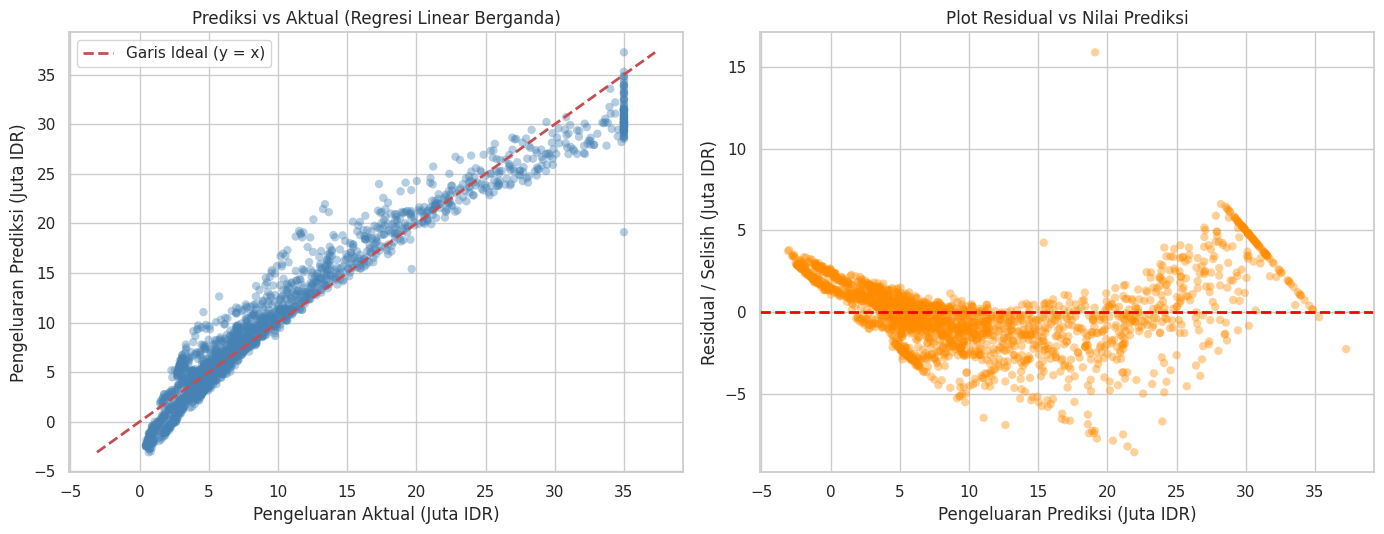


Intercept Model Berganda: Rp -74,579,575
=== 15 Fitur dengan Pengaruh Koefisien Terbesar ===


,Fitur,Koefisien (IDR)
28,cat__seasonality_tier_Low Season Hari Kerja Biasa,"87,421,238"
30,cat__seasonality_tier_Weekend Normal,"58,219,630"
6,num__destination_carrying_capacity_index,"55,127,320"
23,cat__accommodation_type_Tanpa Menginap One-Day-Trip,"38,162,761"
29,cat__seasonality_tier_Peak Season Libur Sekolah,"29,102,587"
22,cat__accommodation_type_Hotel Bintang 4-5 Resort,"28,939,790"
3,num__hotel_occupancy_rate_pct,"-24,057,496"
31,cat__primary_travel_motive_Sport Tourism & Event Internasional,"19,047,603"
21,cat__accommodation_type_Hotel Bintang 1-3,"18,919,607"
33,cat__primary_travel_motive_Wisata Alam & Bahari,"14,662,283"


In [23]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

eval_rows = []
fitted_models = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

    # Prediksi pada data latih & data uji (satu kali)
    y_train_pred = pipe.predict(X_train)
    y_test_pred = pipe.predict(X_test)

    eval_rows.append({
        "Model": name,
        "Train MAE (IDR)": mean_absolute_error(y_train, y_train_pred),
        "Test MAE (IDR)": mean_absolute_error(y_test, y_test_pred),
        "Train RMSE (IDR)": root_mean_squared_error(y_train, y_train_pred),
        "Test RMSE (IDR)": root_mean_squared_error(y_test, y_test_pred),
        "Train R2": r2_score(y_train, y_train_pred),
        "Test R2": r2_score(y_test, y_test_pred),
    })

df_eval = pd.DataFrame(eval_rows)
print("=== Tabel Perbandingan Evaluasi Data Latih vs Data Uji ===")
display(df_eval.style.format({
    "Train MAE (IDR)": "{:,.0f}",
    "Test MAE (IDR)": "{:,.0f}",
    "Train RMSE (IDR)": "{:,.0f}",
    "Test RMSE (IDR)": "{:,.0f}",
    "Train R2": "{:.4f}",
    "Test R2": "{:.4f}",
}))

# --- Visualisasi Prediksi vs Aktual & Plot Residual (Model Regresi Linear Berganda) ---
best_model = fitted_models["Regresi Linear Berganda"]
y_pred_best = best_model.predict(X_test)
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Plot 1: Prediksi vs Aktual
axes[0].scatter(y_test / 1e6, y_pred_best / 1e6, alpha=0.4, color="steelblue", edgecolor="none")
min_val = min(y_test.min(), y_pred_best.min()) / 1e6
max_val = max(y_test.max(), y_pred_best.max()) / 1e6
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Garis Ideal (y = x)")
axes[0].set_title("Prediksi vs Aktual (Regresi Linear Berganda)")
axes[0].set_xlabel("Pengeluaran Aktual (Juta IDR)")
axes[0].set_ylabel("Pengeluaran Prediksi (Juta IDR)")
axes[0].legend()

# Plot 2: Residual Plot
axes[1].scatter(y_pred_best / 1e6, residuals / 1e6, alpha=0.4, color="darkorange", edgecolor="none")
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("Plot Residual vs Nilai Prediksi")
axes[1].set_xlabel("Pengeluaran Prediksi (Juta IDR)")
axes[1].set_ylabel("Residual / Selisih (Juta IDR)")

plt.tight_layout()
plt.savefig("reports/06_evaluasi_prediksi_residual.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Tabel Koefisien Regresi Linear Berganda ---
feature_names_out = best_model.named_steps["preprocessor"].get_feature_names_out()
coefs = best_model.named_steps["regressor"].coef_
intercept = best_model.named_steps["regressor"].intercept_

df_coef = pd.DataFrame({
    "Fitur": feature_names_out,
    "Koefisien (IDR)": coefs,
    "Abs_Koefisien": np.abs(coefs),
}).sort_values(by="Abs_Koefisien", ascending=False).drop(columns="Abs_Koefisien")

print(f"\nIntercept Model Berganda: Rp {intercept:,.0f}")
print("=== 15 Fitur dengan Pengaruh Koefisien Terbesar ===")
display(df_coef.head(15).style.format({"Koefisien (IDR)": "{:,.0f}"}))

### Interpretasi Hasil Evaluasi

1. **Tafsir MAE dalam Satuan Target:**
   Model **Regresi Linear Berganda** memperoleh nilai **Test MAE sebesar Rp 1.639.834**. Artinya, secara rata-rata, selisih antara total pengeluaran wisatawan per orang yang diprediksi model dengan pengeluaran aktualnya pada data uji adalah sekitar **Rp 1,64 juta**. Kesalahan prediksi ini jauh lebih kecil dibandingkan *baseline* `DummyRegressor` (**Rp 7.120.592**, turun sekitar **77,0%**) maupun Regresi Linear Sederhana (**Rp 3.899.657**, turun sekitar **57,9%**).

2. **Pengecekan Overfitting (Perbandingan Data Latih vs Data Uji):**
   Performa model pada data latih dan data uji sangat berdekatan di seluruh metrik:
   - **Train $R^2 = 0.9498$** vs **Test $R^2 = 0.9451$** (selisih hanya `0.0047`).
   - **Train MAE = Rp 1.563.674** vs **Test MAE = Rp 1.639.834** (selisih hanya Rp 76.160).
   Hal ini membuktikan bahwa model **tidak mengalami *overfitting*** maupun *underfitting*, serta mampu melakukan generalisasi dengan sangat baik pada data baru.

3. **Arti Koefisien Model Berganda (Intercept = Rp -74.579.575):**
   - **Fitur Numerik (sudah distandarisasi dengan `StandardScaler`):** Kenaikan sebesar **1 standar deviasi** pada `destination_carrying_capacity_index` meningkatkan prediksi pengeluaran per orang sebesar **+Rp 55.127.320**, sedangkan kenaikan 1 standar deviasi pada `tourism_economic_multiplier_score` menambah prediksi sebesar **+Rp 12.628.805** (dengan asumsi variabel lain tetap). Sebaliknya, `hotel_occupancy_rate_pct` memiliki koefisien negatif (**-Rp 24.057.496** per 1 standar deviasi), yang mencerminkan penyesuaian efek multivariat ketika variabel musim dan kapasitas destinasi dikendalikan bersamaan.
   - **Fitur Kategorik (hasil *One-Hot Encoding* dengan `drop="first"`):** Koefisien menunjukkan selisih rata-rata pengeluaran terhadap kategori referensi (*baseline category* masing-masing kolom). Misalnya pada jenis akomodasi, segmen `Hotel Bintang 4-5 Resort` memberikan tambahan **+Rp 28.939.790** dan `Villa / Glamping Ekologis` memberikan **+Rp 9.752.945** dibandingkan kategori referensi akomodasi, sedangkan pada motif perjalanan, `Sport Tourism & Event Internasional` menambah **+Rp 19.047.603**.

4. **Analisis Grafik Prediksi vs Aktual & Plot Residual:**
   Pada grafik **Prediksi vs Aktual**, titik-titik prediksi berhimpit rapat mengikuti garis diagonal ideal ($y = x$), menegaskan akurasi tinggi model. Pada **Plot Residual**, sebaran galat terpusat di sekitar garis nol, namun terlihat sedikit pola lengkungan di ujung bawah dan batas atas sekitar Rp 35 juta akibat adanya batas nilai pengeluaran maksimum (*capping*) pada dataset serta hubungan non-linear ringan antar variabel.

### Keputusan saya
Saya menetapkan **Regresi Linear Berganda** sebagai model akhir terbaik karena mampu menjelaskan **94,51%** variasi total pengeluaran wisatawan per orang pada data uji (**Test $R^2 = 0.9451$**), bebas dari *overfitting*, dan berhasil menekan kesalahan rata-rata prediksi (MAE) hingga **Rp 1.639.834** dibandingkan *baseline* (Rp 7.120.592).

---

## 6. Kesimpulan

### Kelayakan dan Pemilihan Model
Model **Regresi Linear Berganda** **sangat layak digunakan** sebagai alat bantu estimasi pengeluaran wisatawan dibandingkan *baseline* `DummyRegressor` maupun Regresi Linear Sederhana, berdasarkan dua alasan kuantitatif utama pada data uji:
1. **Penurunan Kesalahan Prediksi (MAE & RMSE) yang Signifikan:** Test MAE berhasil diturunkan dari **Rp 7.120.592** (baseline) dan **Rp 3.899.657** (regresi sederhana) menjadi **Rp 1.639.834** (turun **77,0%** dari baseline), diikuti penurunan Test RMSE dari **Rp 9.294.470** menjadi **Rp 2.175.419**.
2. **Daya Jelaskan Tinggi ($R^2$) dan Bebas Overfitting:** Regresi Linear Berganda meraih **Test $R^2 = 0.9451$** (jauh melampaui baseline `-0.0016` dan regresi sederhana `0.6785`) dengan selisih terhadap Train $R^2$ (`0.9498`) sebesar `0.0047`, menunjukkan stabilitas generalisasi yang tinggi.

### Rekomendasi Tindakan bagi Pengguna
- **Bagi Pengelola Hotel, Resor, & UMKM Pariwisata:** Optimalkan paket *bundling* menginap dan aktivitas wisata pada segmen akomodasi kelas atas (`Hotel Bintang 4-5 Resort`, `Villa / Glamping Ekologis`) serta wisatawan dengan durasi tinggal lebih lama, karena kombinasi lama kunjungan, jenis akomodasi, dan asal wisatawan memberikan kontribusi belanja per orang tertinggi.
- **Bagi Dinas Pariwisata & Pengelola Destinasi:** Tingkatkan daya dukung kapasitas destinasi (`destination_carrying_capacity_index`) serta selenggarakan agenda berskala internasional (`Sport Tourism & Event Internasional`) dan ekowisata, karena keduanya terbukti berkorelasi positif kuat dengan peningkatan pengeluaran wisatawan per kunjungan.

### Keterbatasan dan Saran Perbaikan
- **Keterbatasan:** Model regresi linear mengasumsikan hubungan aditif garis lurus antar fitur sehingga menghasilkan sedikit prediksi negatif pada kasus pengeluaran sangat rendah dan pola lengkungan residual pada batas pengeluaran maksimum (Rp 35 juta).
- **Saran Perbaikan:** Pada pengembangan berikutnya dapat ditambahkan fitur interaksi (seperti perkalian `trip_duration_days` × `hotel_room_rate_per_night_idr`), transformasi target logaritmik ($\log(y)$) agar prediksi selalu bernilai positif, serta pengujian algoritma non-linear seperti *Random Forest Regressor* atau *Gradient Boosting*.

### Keputusan saya
Seluruh tahapan CRISP-DM telah diselesaikan menggunakan `SEED = 714` sesuai tiga digit terakhir NIM `2301010714`. Model final yang dipilih adalah **Regresi Linear Berganda** dengan **Test $R^2 = 0.9451$** dan **Test MAE = Rp 1.639.834**, dan seluruh artefak grafik telah tersimpan di folder `reports/` untuk kebutuhan dokumentasi GitHub serta presentasi.